<a href="https://colab.research.google.com/github/Ashwini-Patil-05/GWO/blob/main/TSNE.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.impute import SimpleImputer
from sklearn.manifold import TSNE

In [2]:
from google.colab import files

uploaded = files.upload()


df = pd.read_csv('/content/archive (7).zip')

print(df.shape)
df.head()

Saving archive (7).zip to archive (7) (1).zip
(9551, 21)


,Restaurant ID,Restaurant Name,Country Code,City,Address,Locality,Locality Verbose,Longitude,Latitude,Cuisines,...,Currency,Has Table booking,Has Online delivery,Is delivering now,Switch to order menu,Price range,Aggregate rating,Rating color,Rating text,Votes
0,6317637,Le Petit Souffle,162,Makati City,"Third Floor, Century City Mall, Kalayaan Avenu...","Century City Mall, Poblacion, Makati City","Century City Mall, Poblacion, Makati City, Mak...",121.027535,14.565443,"French, Japanese, Desserts",...,Botswana Pula(P),Yes,No,No,No,3,4.8,Dark Green,Excellent,314
1,6304287,Izakaya Kikufuji,162,Makati City,"Little Tokyo, 2277 Chino Roces Avenue, Legaspi...","Little Tokyo, Legaspi Village, Makati City","Little Tokyo, Legaspi Village, Makati City, Ma...",121.014101,14.553708,Japanese,...,Botswana Pula(P),Yes,No,No,No,3,4.5,Dark Green,Excellent,591
2,6300002,Heat - Edsa Shangri-La,162,Mandaluyong City,"Edsa Shangri-La, 1 Garden Way, Ortigas, Mandal...","Edsa Shangri-La, Ortigas, Mandaluyong City","Edsa Shangri-La, Ortigas, Mandaluyong City, Ma...",121.056831,14.581404,"Seafood, Asian, Filipino, Indian",...,Botswana Pula(P),Yes,No,No,No,4,4.4,Green,Very Good,270
3,6318506,Ooma,162,Mandaluyong City,"Third Floor, Mega Fashion Hall, SM Megamall, O...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.056475,14.585318,"Japanese, Sushi",...,Botswana Pula(P),No,No,No,No,4,4.9,Dark Green,Excellent,365
4,6314302,Sambo Kojin,162,Mandaluyong City,"Third Floor, Mega Atrium, SM Megamall, Ortigas...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.057508,14.584450,"Japanese, Korean",...,Botswana Pula(P),Yes,No,No,No,4,4.8,Dark Green,Excellent,229


In [3]:
# Remove duplicate records
df = df.drop_duplicates()

# Select useful numerical columns
data = df[
    ['Country Code', 'Longitude', 'Latitude',
     'Average Cost for two', 'Price range',
     'Aggregate rating', 'Votes']
].copy()

# Handle missing values
imputer = SimpleImputer(strategy='median')
data = pd.DataFrame(imputer.fit_transform(data), columns=data.columns)

# Scale the data
scaler = StandardScaler()
scaled_data = scaler.fit_transform(data)

print("Preprocessing completed!")
print(scaled_data.shape)

Preprocessing completed!
(9551, 7)


In [4]:
tsne = TSNE(
    n_components=2,
    perplexity=30,
    learning_rate='auto',
    init='pca',
    random_state=42,
    max_iter=1000
)

tsne_result = tsne.fit_transform(scaled_data)

print("t-SNE applied successfully!")

t-SNE applied successfully!


In [5]:
tsne_df = pd.DataFrame({
    'TSNE_1': tsne_result[:, 0],
    'TSNE_2': tsne_result[:, 1],
    'Rating': df.loc[data.index, 'Aggregate rating'].values
})

tsne_df.head()

,TSNE_1,TSNE_2,Rating
0,71.412552,-1.864599,4.8
1,71.010773,-2.044088,4.5
2,70.311562,-1.163084,4.4
3,70.250343,-1.256718,4.9
4,70.331818,-1.135918,4.8


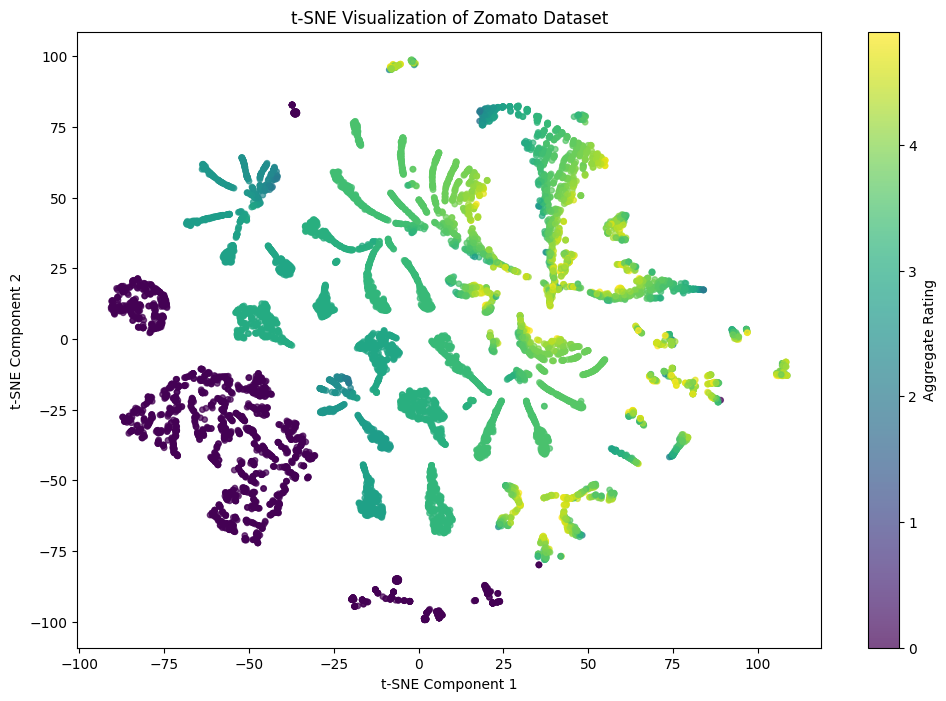

In [6]:
plt.figure(figsize=(12, 8))

scatter = plt.scatter(
    tsne_df['TSNE_1'],
    tsne_df['TSNE_2'],
    c=tsne_df['Rating'],
    cmap='viridis',
    s=15,
    alpha=0.7
)

plt.colorbar(scatter, label='Aggregate Rating')

plt.title('t-SNE Visualization of Zomato Dataset')
plt.xlabel('t-SNE Component 1')
plt.ylabel('t-SNE Component 2')

plt.show()